In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

SEMILLA = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

crudo = pd.read_csv(dato("reservas_sucio.csv"))
print(crudo.shape)

(1545, 18)


In [2]:
def resumen_calidad(tabla):
    return pd.DataFrame({
        "tipo": tabla.dtypes.astype(str),
        "nulos": tabla.isna().sum(),
        "pct_nulos": (tabla.isna().mean() * 100).round(2),
        "distintos": tabla.nunique(),
    })

resumen_calidad(crudo)

,tipo,nulos,pct_nulos,distintos
id_reserva,int64,0,0.00,1500
fecha_reserva,object,0,0.00,753
fecha_llegada,object,0,0.00,677
antelacion_dias,int64,0,0.00,264
noches,int64,0,0.00,17
adultos,float64,46,2.98,4
ninos,int64,0,0.00,4
tipo_habitacion,object,0,0.00,4
regimen,object,61,3.95,4
canal,object,0,0.00,9


In [3]:
print("Filas duplicadas exactas:", crudo.duplicated().sum())
print("Precios escritos con coma:", crudo["precio_noche"].astype(str).str.contains(",").sum())
iso = pd.to_datetime(crudo["fecha_reserva"], format="%Y-%m-%d", errors="coerce")
espanol = pd.to_datetime(crudo["fecha_reserva"], format="%d/%m/%Y", errors="coerce")
print("Fechas ISO:", iso.notna().sum(), "· dd/mm/aaaa:", espanol.notna().sum(), "· sin leer:", (iso.isna() & espanol.isna()).sum())
crudo[["fecha_reserva", "precio_noche"]].head(8)

Filas duplicadas exactas: 45
Precios escritos con coma: 153
Fechas ISO: 1391 · dd/mm/aaaa: 154 · sin leer: 0


,fecha_reserva,precio_noche
0,2025-11-09,84.36
1,19/11/2024,74.14
2,22/01/2025,NaN
3,2025-08-07,93.82
4,2024-03-03,NaN
5,2024-09-20,77.77
6,2024-09-01,81.02
7,02/11/2025,73.2


In [4]:
print(crudo["canal"].value_counts().to_string())
print()
print(crudo["pais_origen"].value_counts().to_string())

canal
web_intermediaria     718
directo               311
agencia               297
empresa                84
WEB_INTERMEDIARIA      34
Web Intermediaria      33
web intermediaria      28
Directo                24
directo                16

pais_origen
ES             351
UK             316
DE             223
otros          145
Nordicos        88
NL              78
IT              78
FR              57
España          26
es              23
uk              23
Reino Unido     22


In [5]:
print(crudo["tipo_habitacion"].value_counts().to_string())
print()
print(crudo["regimen"].value_counts().to_string())
print()
print(crudo["tarifa"].value_counts().to_string())
print()
print(crudo["deposito"].value_counts().to_string())

tipo_habitacion
estandar    764
superior    414
familiar    217
suite       150

regimen
desayuno            602
todo_incluido       349
media_pension       315
solo_alojamiento    218

tarifa
flexible           928
no_reembolsable    617

deposito
sin_deposito    852
parcial         476
total           217


In [6]:
precio = pd.to_numeric(crudo["precio_noche"].astype(str).str.replace(",", "."), errors="coerce")
print(precio.describe().round(1))
print("Precios <= 0:", (precio <= 0).sum(), "· precios > 1000:", (precio > 1000).sum())
print("Noches <= 0:", (crudo["noches"] <= 0).sum())
print("Antelaciones negativas:", (crudo["antelacion_dias"] < 0).sum())

count    1461.0
mean      129.6
std       518.4
min       -50.0
25%        78.0
50%        93.3
75%       120.0
max      9999.0
Name: precio_noche, dtype: float64
Precios <= 0: 4 · precios > 1000: 4
Noches <= 0: 6
Antelaciones negativas: 5


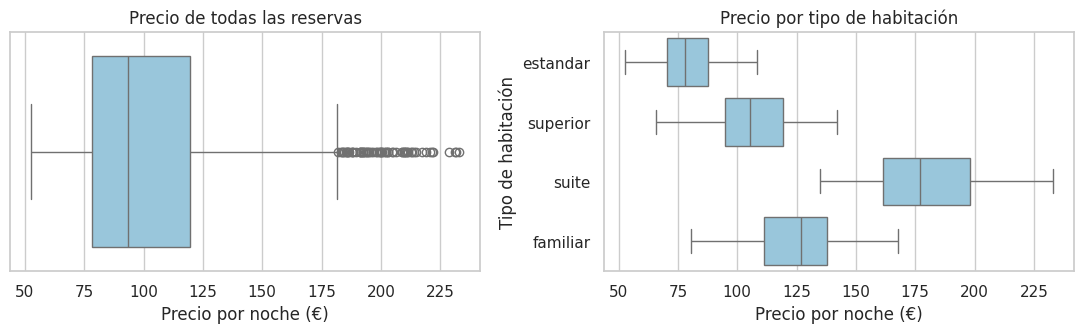

In [7]:
precio_ok = precio[precio.between(1, 1000)]
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=precio_ok, ax=ejes[0], color="#8ecae6")
ejes[0].set(title="Precio de todas las reservas", xlabel="Precio por noche (€)")
sns.boxplot(x=precio_ok, y=crudo.loc[precio_ok.index, "tipo_habitacion"], ax=ejes[1], color="#8ecae6")
ejes[1].set(title="Precio por tipo de habitación", xlabel="Precio por noche (€)", ylabel="Tipo de habitación")
plt.tight_layout()
plt.show()

In [8]:
nulos = crudo.isna().sum()
print(nulos[nulos > 0])
fecha_reserva = iso.fillna(espanol)
fecha_llegada = pd.to_datetime(crudo["fecha_llegada"], format="%Y-%m-%d")
antelacion_calculada = (fecha_llegada - fecha_reserva).dt.days
print("Antelaciones que no cuadran con las fechas:", (antelacion_calculada != crudo["antelacion_dias"]).sum())

adultos          46
regimen          61
pais_origen     115
precio_noche     84
dtype: int64
Antelaciones que no cuadran con las fechas: 5


In [9]:
EQUIV_PAIS = {"es": "ES", "españa": "ES", "uk": "UK", "reino unido": "UK", "de": "DE",
              "nl": "NL", "it": "IT", "fr": "FR", "nordicos": "Nordicos", "otros": "otros"}

def limpiar_reservas(tabla):
    """Limpia reservas_sucio.csv con reglas fijas y devuelve (tabla_limpia, resumen).

    No modifica la tabla que recibe: trabaja sobre una copia.
    Solo aplica reglas que no dependen de los datos (no calcula medias ni medianas).
    El resumen cuenta lo que ha cambiado: filas quitadas, valores imposibles pasados a nulo, etc.
    """
    t = tabla.copy()
    resumen = {"filas_antes": len(t)}

    t = t.drop_duplicates().reset_index(drop=True)
    resumen["duplicados_quitados"] = resumen["filas_antes"] - len(t)

    t["precio_noche"] = pd.to_numeric(t["precio_noche"].astype(str).str.replace(",", "."), errors="coerce")
    iso = pd.to_datetime(t["fecha_reserva"], format="%Y-%m-%d", errors="coerce")
    espanol = pd.to_datetime(t["fecha_reserva"], format="%d/%m/%Y", errors="coerce")
    t["fecha_reserva"] = iso.fillna(espanol)
    t["fecha_llegada"] = pd.to_datetime(t["fecha_llegada"], format="%Y-%m-%d")

    t["canal"] = t["canal"].str.strip().str.lower().str.replace(" ", "_")
    t["pais_origen"] = t["pais_origen"].str.strip().str.lower().map(EQUIV_PAIS)

    nulos_antes = t[["precio_noche", "noches"]].isna().sum().sum()
    t["precio_noche"] = t["precio_noche"].where(t["precio_noche"].between(20, 1000))
    t["noches"] = t["noches"].where(t["noches"].between(1, 60))
    resumen["imposibles_a_nulo"] = int(t[["precio_noche", "noches"]].isna().sum().sum() - nulos_antes)

    antelacion_vieja = t["antelacion_dias"]
    t["antelacion_dias"] = (t["fecha_llegada"] - t["fecha_reserva"]).dt.days
    resumen["antelaciones_recalculadas"] = int((t["antelacion_dias"] != antelacion_vieja).sum())

    t["mes_llegada"] = t["fecha_llegada"].dt.month
    resumen["filas_despues"] = len(t)
    return t, resumen

In [10]:
limpia, resumen = limpiar_reservas(crudo)
print(resumen)
print(crudo.shape, limpia.shape)

{'filas_antes': 1545, 'duplicados_quitados': 45, 'imposibles_a_nulo': 14, 'antelaciones_recalculadas': 5, 'filas_despues': 1500}
(1545, 18) (1500, 19)


In [11]:
antes_despues = pd.DataFrame({
    "antes": [len(crudo), crudo.duplicated().sum(), crudo["canal"].nunique(), crudo["pais_origen"].nunique()],
    "después": [len(limpia), limpia.duplicated().sum(), limpia["canal"].nunique(), limpia["pais_origen"].nunique()],
}, index=["filas", "duplicados", "valores distintos de canal", "valores distintos de país"])
antes_despues

,antes,después
filas,1545,1500
duplicados,45,0
valores distintos de canal,9,4
valores distintos de país,12,8


In [12]:
nulos = pd.DataFrame({"antes": crudo.isna().sum(), "después": limpia[crudo.columns].isna().sum()})
nulos[nulos.sum(axis=1) > 0]

,antes,después
noches,0,6
adultos,46,46
regimen,61,59
pais_origen,115,112
precio_noche,84,87


In [13]:
print(limpia["fecha_reserva"].min().date(), limpia["fecha_reserva"].max().date())

2024-01-01 2025-12-30


In [14]:
# Definición de las variables con las columnas numéricas y categóricas
columnas_num = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche", "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "mes_llegada"]
columnas_cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]

# Partición temporal: entrenar con reservas anteriores y probar con reservas posteriores.
# La fecha de reserva es la referencia temporal: es conocida cuando se realiza la reserva.
orden = limpia.sort_values("fecha_reserva", kind="stable").copy()

# Corte cronológico en el percentil 80 de las fechas.
fecha_corte = orden["fecha_reserva"].quantile(0.80)

train = orden[orden["fecha_reserva"] < fecha_corte].copy()
test = orden[orden["fecha_reserva"] >= fecha_corte].copy()

X_train = train[columnas_num + columnas_cat]
X_test = test[columnas_num + columnas_cat]
y_train = train["cancelada"]
y_test = test["cancelada"]

print("Fecha de corte:", fecha_corte)
print("Periodo train:", train["fecha_reserva"].min(), "→", train["fecha_reserva"].max())
print("Periodo test:", test["fecha_reserva"].min(), "→", test["fecha_reserva"].max())
print("Tamaños:", X_train.shape, X_test.shape)
print("Proporción canceladas:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Fecha de corte: 2025-08-07 04:48:00
Periodo train: 2024-01-01 00:00:00 → 2025-08-07 00:00:00
Periodo test: 2025-08-08 00:00:00 → 2025-12-30 00:00:00
Tamaños: (1200, 15) (300, 15)
Proporción canceladas: 0.463 0.5


In [15]:
import sys, pandas, sklearn

print(sys.version, pandas.__version__, sklearn.__version__)

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0] 2.2.3 1.6.1


## Paso 4 y nivel extra · Pipeline, modelos y validación temporal

En estas celdas completamos el nivel estándar y extra. El preprocesado se ajusta dentro del pipeline, de modo que en cada pliegue de validación solo aprende de la parte de entrenamiento.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import roc_auc_score, classification_report

# Preprocesado numérico: imputar mediana y escalar.
pre_num = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler())
])

# Preprocesado categórico: imputar moda y crear variables indicadoras.
pre_cat = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("codificar", OneHotEncoder(handle_unknown="ignore"))
])

preprocesado = ColumnTransformer([
    ("num", pre_num, columnas_num),
    ("cat", pre_cat, columnas_cat)
])

print("Pipeline de preprocesado preparado.")

Pipeline de preprocesado preparado.


### Validación cruzada temporal

`TimeSeriesSplit` conserva el orden cronológico: cada validación utiliza observaciones posteriores a las usadas para entrenar. El pipeline se vuelve a ajustar dentro de cada pliegue, evitando que el imputador, el escalador o el codificador aprendan de la validación.

In [17]:
# Los datos de train ya están ordenados por fecha de reserva.
cv_temporal = TimeSeriesSplit(n_splits=5)

modelos = {
    "DummyClassifier": Pipeline([
        ("preprocesado", preprocesado),
        ("modelo", DummyClassifier(strategy="most_frequent"))
    ]),
    "Regresión logística": Pipeline([
        ("preprocesado", preprocesado),
        ("modelo", LogisticRegression(max_iter=1000, random_state=SEMILLA))
    ])
}

resultados_cv = []
for nombre, modelo in modelos.items():
    scores = cross_validate(
        modelo, X_train, y_train,
        cv=cv_temporal,
        scoring="roc_auc",
        return_train_score=False
    )
    media = scores["test_score"].mean()
    desviacion = scores["test_score"].std()
    resultados_cv.append({
        "modelo": nombre,
        "AUC_media": media,
        "AUC_desviacion": desviacion
    })

tabla_cv = pd.DataFrame(resultados_cv)
tabla_cv.round(3)

,modelo,AUC_media,AUC_desviacion
0,DummyClassifier,0.500,0.000
1,Regresión logística,0.746,0.023


### Entrenar con todo train y evaluar una sola vez en test

Una vez comparados los modelos mediante validación cruzada temporal, ajustamos la regresión logística con todo el conjunto train. El conjunto test se utiliza únicamente para la evaluación final.

In [18]:
modelo_final = modelos["Regresión logística"]
modelo_final.fit(X_train, y_train)

probabilidades_test = modelo_final.predict_proba(X_test)[:, 1]
auc_test = roc_auc_score(y_test, probabilidades_test)

print("AUC en test temporal:", round(auc_test, 3))

AUC en test temporal: 0.737


## Nivel extra · Demostración de fuga de datos al escalar

El escalador debe aprender la media y la desviación típica solo con train. Si se ajusta con train y test juntos, incorpora información de la distribución del periodo futuro. Aunque no utiliza directamente la etiqueta, sí contamina el proceso de evaluación.

In [19]:
# Demostración con las columnas numéricas.
# Se usan los datos temporales ya separados.
imputador_demo = SimpleImputer(strategy="median")
train_num = imputador_demo.fit_transform(X_train[columnas_num])
test_num = imputador_demo.transform(X_test[columnas_num])

# Forma correcta: el escalador aprende solo de train.
escalador_correcto = StandardScaler()
train_escalado_correcto = escalador_correcto.fit_transform(train_num)
test_escalado_correcto = escalador_correcto.transform(test_num)

# Forma incorrecta: el escalador aprende también de test (fuga).
todos_num = np.vstack([train_num, test_num])
escalador_con_fuga = StandardScaler()
todos_escalados_con_fuga = escalador_con_fuga.fit_transform(todos_num)

print("Media aprendida correctamente (primeras 3 columnas):",
      escalador_correcto.mean_[:3].round(2))
print("Media aprendida con fuga (primeras 3 columnas):",
      escalador_con_fuga.mean_[:3].round(2))
print("Diferencia absoluta entre medias (primeras 3 columnas):",
      np.abs(escalador_correcto.mean_[:3] - escalador_con_fuga.mean_[:3]).round(2))

Media aprendida correctamente (primeras 3 columnas): [89.93  5.52  2.24]
Media aprendida con fuga (primeras 3 columnas): [89.04  5.49  2.23]
Diferencia absoluta entre medias (primeras 3 columnas): [0.89 0.03 0.  ]


**Interpretación que debe quedar en el informe:** el segundo escalador utiliza también la distribución de test para calcular sus parámetros. Esto es fuga de información del conjunto de evaluación. La evaluación válida utiliza el pipeline, que ajusta imputación, escalado y codificación solo con train en cada pliegue. La magnitud de las diferencias impresas depende de los datos; no se debe afirmar que la fuga mejora siempre la métrica.

## IA responsable · país de origen

Comprobar la proporción de cancelaciones y el tamaño de cada grupo. No interpretar diferencias de grupos pequeños como conclusiones firmes y no imputar automáticamente todos los países ausentes con una nacionalidad concreta.

In [20]:
print(limpia.groupby("pais_origen")["cancelada"].agg(["mean", "count"]).round(2))
print("Países ausentes:", limpia["pais_origen"].isna().sum(),
      "· proporción:", round(limpia["pais_origen"].isna().mean(), 3))

             mean  count
pais_origen             
DE           0.49    219
ES           0.45    388
FR           0.46     56
IT           0.60     77
NL           0.37     75
Nordicos     0.47     85
UK           0.48    349
otros        0.43    139
Países ausentes: 112 · proporción: 0.075
